In [10]:
from astropy.table import Table
import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk
import glob
import pandas as pd
from astropy.time import Time
from astroquery.vizier import Vizier
from astropy.timeseries import LombScargle

In [2]:
asas_lc = Table.read("data/asas_lc.csv",format="ascii")
asas_sn_lc = pd.read_csv("data/hd_104919_asas_sn_lc.csv", header=5)
asas_sn_lc = Table.from_pandas(asas_sn_lc)
asas_sn_lc = asas_sn_lc[asas_sn_lc['Quality'] == 'G']

In [3]:
asas_sn_lc

JD,Flux,Flux Error,Mag,Mag Error,Limit,FWHM,Filter,Quality,Camera
float64,float64,float64,float64,float64,float64,float64,str1,str1,str2
2457437.6798849,672.4255,0.4387,9.3907,0.0007,15.607,1.34,V,G,bh
2457447.8267438,636.4453,0.2153,9.4504,0.0004,16.3797,1.39,V,G,bh
2457451.7600056,656.1573,0.3473,9.4173,0.0006,15.8606,1.33,V,G,bh
2457454.8455465,640.9207,0.2601,9.4428,0.0004,16.1747,1.45,V,G,bh
2457457.651585,656.8668,0.3537,9.4161,0.0006,15.8406,1.34,V,G,bh
2457476.8438372,658.048,0.3643,9.4141,0.0006,15.8087,1.37,V,G,bh
2457477.6110633,648.0147,0.293,9.4308,0.0005,16.0451,1.35,V,G,bh
2457481.6651,686.1233,0.4907,9.3688,0.0008,15.4854,1.34,V,G,bh
2457548.7065145,611.1745,0.2808,9.4944,0.0005,16.0914,1.62,V,G,bh


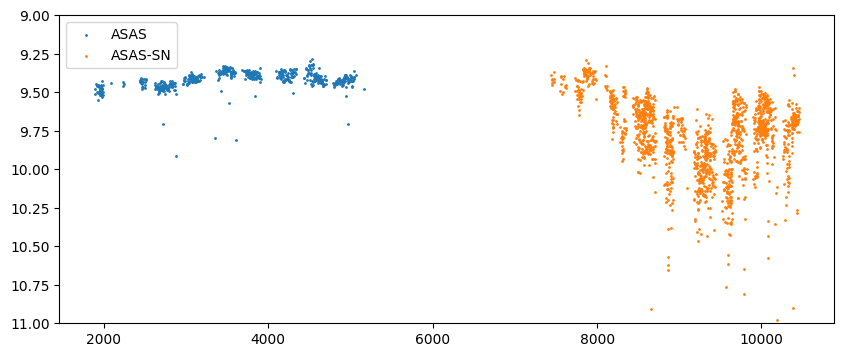

In [4]:
plt.figure(figsize=(10,4))
plt.scatter(asas_lc['HJD'].value, asas_lc['MAG_2'].value, s=1, label = 'ASAS')
plt.scatter(asas_sn_lc['JD']-2450000, asas_sn_lc['Mag'], s=1, label = 'ASAS-SN')
plt.ylim(9,11)
plt.gca().invert_yaxis()
plt.legend()

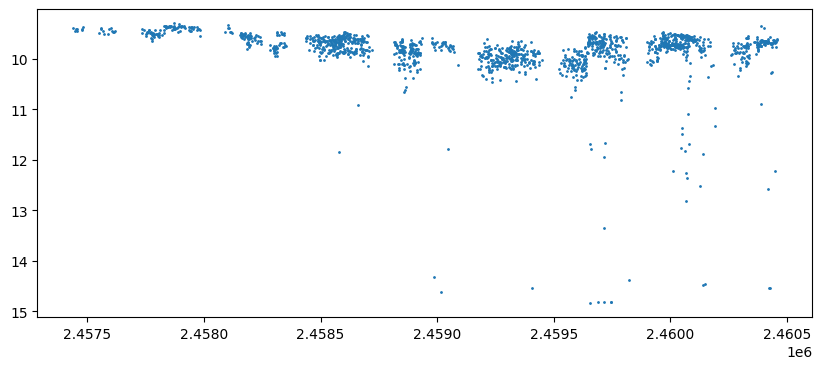

In [7]:
plt.figure(figsize=(10,4))
plt.scatter(asas_sn_lc['JD'], asas_sn_lc['Mag'], s=1, label = 'ASAS-SN')
plt.gca().invert_yaxis()

In [50]:
tess_lk = lk.search_lightcurve('HD 104919', author='QLP').download_all().stitch()

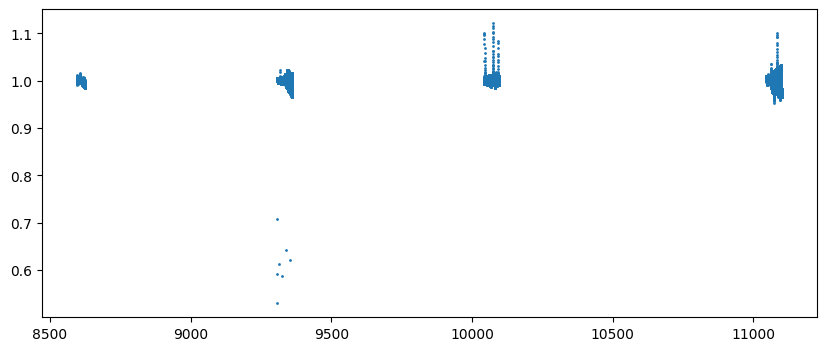

In [51]:
plt.figure(figsize=(10,4))

plt.scatter(tess_lk.time.value+7000, tess_lk.flux.value, s=1)

On the same plot:

In [110]:
t = Time("2023-12-14 02:00:00", format="iso", scale="utc")
t.jd - 2450000

np.float64(10292.583333333489)

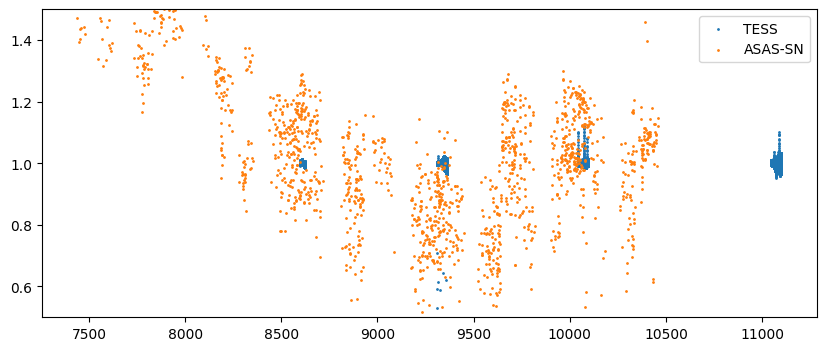

In [113]:
plt.figure(figsize=(10,4))
# plt.scatter(asas_lc['HJD'].value, asas_lc['MAG_2'].value/np.nanmedian(asas_lc['MAG_2'].value), s=1)
plt.scatter(tess_lk.time.value+7000, tess_lk.flux.value,s=1, label='TESS')
plt.scatter(asas_sn_lc['JD'] - 2450000, asas_sn_lc['Flux']/np.nanmedian(asas_sn_lc['Flux']), s=1, label = 'ASAS-SN')
plt.ylim(0.5,1.5)
# plt.xlim(t.jd - 2450000 - 3.5, t.jd - 2450000 + 3.5)
# plt.axvline(t.jd - 2450000)
plt.legend()
plt.show()

Xray detections

In [91]:
result = Vizier.query_object("1RXS J120448.2-640942", catalog="IX/10A")

In [108]:
result[0]

1RXS,RAJ2000,DEJ2000,PosErr,NewFlag,Count,e_Count,HR1,e_HR1,HR2,e_HR2
,deg,deg,arcsec,,ct / s,ct / s,,,,
str16,float64,float64,int16,str4,float32,float32,float32,float32,float32,float32
J120448.2-640942,181.20084,-64.16180,9,__..,0.35,0.042,0.46,0.11,0.06,0.14


# Lomb Scargle

In [8]:
def calc_lomb_scargle(t, y):

    # remove NaNs
    mask = np.isfinite(t) & np.isfinite(y)
    t = t[mask]
    y = y[mask]

    # remove mean
    y = y - np.mean(y)

    oversample = 10

    tspan = t.max() - t.min()
    df = 1.0 / tspan

    fmin = df
    fmax = 25  # cycles/day

    freq = np.arange(fmin, fmax, df / oversample)

    model = LombScargle(t, y)
    power = model.power(freq)

    # simple amplitude estimate (relative, not absolute physical ppm)
    amp = np.sqrt(power)

    return freq, amp

In [11]:
freq, amp = calc_lomb_scargle(asas_sn_lc['JD'], asas_sn_lc['Flux'])

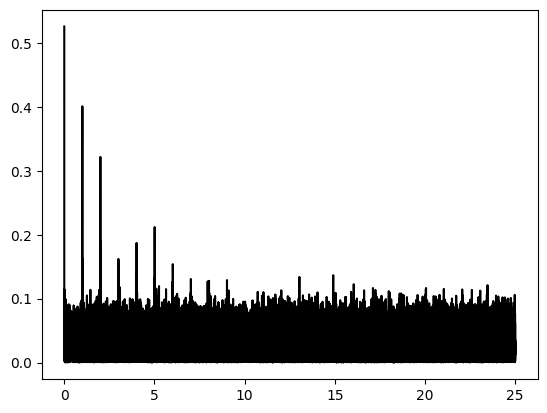

In [17]:
plt.plot(freq, amp, c = 'black')
# plt.xlim(0,5)